<a href="https://colab.research.google.com/github/Antx0x/PMP-2026/blob/main/Partial/Partial_PMP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  **Partial - PMP** - Izbinda Antonio-Vlad 3A3

Subiectul 1
a)

In [2]:
import numpy as np

states = [1, 2, 3, 4]
observations = ['red', 'green', 'blue', 'blue', 'red']
obs_index = {'red': 0, 'green': 1, 'blue': 2}

pi = np.ones(4) / 4

B = np.array([
    [0.7, 0.2, 0.1],
    [0.2, 0.6, 0.2],
    [0.1, 0.3, 0.6],
    [0.5, 0.2, 0.3]
])

A = np.array([
    [0.2, 0.4, 0.0, 0.4],
    [0.4, 0.2, 0.4, 0.0],
    [0.0, 0.4, 0.2, 0.4],
    [0.4, 0.0, 0.4, 0.2]
])

obs = [obs_index[o] for o in observations]

Algoritmul Viterbi


In [3]:
def viterbi(pi, A, B, obs):
    T, N = len(obs), len(pi)
    delta = np.zeros((T, N))
    psi = np.zeros((T, N), dtype=int)

    delta[0] = pi * B[:, obs[0]]

    for t in range(1, T):
        for j in range(N):
            v = delta[t-1] * A[:, j]
            psi[t, j] = np.argmax(v)
            delta[t, j] = np.max(v) * B[j, obs[t]]

    path = np.zeros(T, dtype=int)
    path[-1] = np.argmax(delta[-1])

    for t in range(T-2, -1, -1):
        path[t] = psi[t+1, path[t+1]]

    return path + 1, delta[-1, path[-1]]

path_a, prob_a = viterbi(pi, A, B, obs)
print("Secventa:", path_a)
print("Probabilitatea comuna:", prob_a)

Secventa: [1 2 3 4 1]
Probabilitatea comuna: 0.00033868799999999997


1. b)

In [4]:
A_no_stay = np.array([
    [0.0, 0.5, 0.0, 0.5],
    [0.5, 0.0, 0.5, 0.0],
    [0.0, 0.5, 0.0, 0.5],
    [0.5, 0.0, 0.5, 0.0]
])

path_b, prob_b = viterbi(pi, A_no_stay, B, obs)
print("Secventa:", path_b)
print("Probabilitatea comuna:", prob_b)

Secventa: [1 2 3 4 1]
Probabilitatea comuna: 0.0008268749999999999


în cazul (b), robotul este obligat să schimbe camera la fiecare pas. Se compară secvențele optime și probabilitățile comune obținute în cele două cazuri.

Subiectul 2

a)

Graful are muchiile $A-B$, $B-C$, $C-D$, $D-E$.

Condiționat de B și C, singurul factor care depinde de A este $\\phi_1(A,B)$.

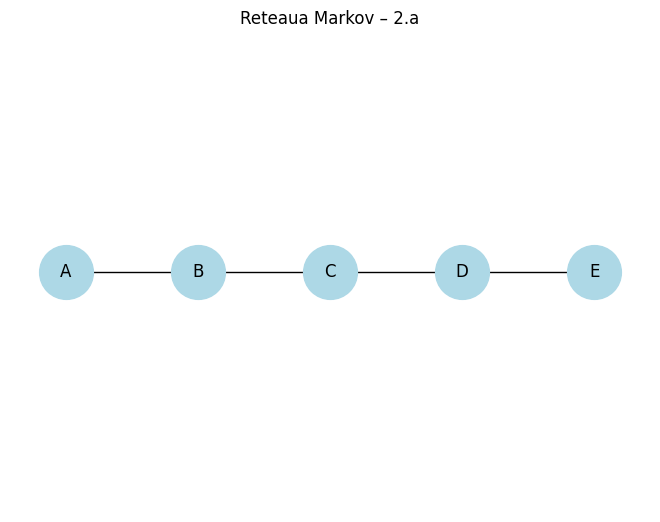

In [5]:
import matplotlib.pyplot as plt
import networkx as nx

G1 = nx.Graph()
G1.add_edges_from([('A','B'), ('B','C'), ('C','D'), ('D','E')])
pos1 = {'A':(0,0), 'B':(1,0), 'C':(2,0), 'D':(3,0), 'E':(4,0)}
nx.draw(G1, pos1, with_labels=True, node_size=1500, node_color='lightblue')
plt.title('Reteaua Markov – 2.a')
plt.show()

2. b)

Graful conține clipele (A,B,C), (B,D), (C,E), deci muchiile $A-B$, $A-C$, $B-C$, $B-D$ și $C-E$.

Condiționat de A, B, C și E, singurul factor care depinde de D este $\\psi_2(B,D)$.


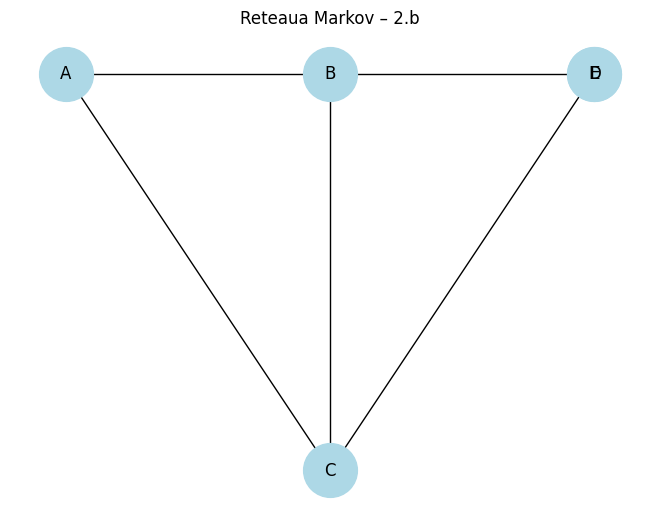

In [10]:
G2 = nx.Graph()
G2.add_edges_from([('A','B'), ('A','C'), ('B','C'), ('B','D'), ('C','E')])
pos2 = {'A':(0,1), 'B':(1,1), 'C':(1,0), 'D':(2,1), 'E':(2,1)}
nx.draw(G2, pos2, with_labels=True, node_size=1500, node_color='lightblue')
plt.title('Reteaua Markov – 2.b')
plt.show()


Subiectul 3

## Subiectul 3

Distribuția a priori:

$$
\theta \sim Beta(2,8)
$$

Pentru o distribuție Beta-Binomial, distribuția a posteriori este:

$$
\theta|D \sim Beta(\alpha+y,\beta+n-y)
$$

Media distribuției Beta:

$$
E[\theta]=\frac{\alpha}{\alpha+\beta}
$$

### 3.a)

$$
\theta|D_1 \sim Beta(2+5,8+20-5)
$$

$$
 {\theta|D_1 \sim Beta(7,23)}
$$


$$
E[\theta|D_1]=\frac{7}{7+23}
={0.233}
$$

### 3.b)

Total produse: 20+15=35

Total defecte: 5+3=8

$$
\theta|D_1,D_2 \sim
Beta(2+5+3,8+15+12)
$$

$$
 {\theta|D_1,D_2 \sim Beta(10,35)}
$$

### 3.c)

Al doilea lot: 3 defecte din 15.

Folosim distribuția inițială Beta(2,8):

$$
\theta|D_2 \sim Beta(2+3,8+15-3)
$$

$$
 {\theta|D_2 \sim Beta(5,20)}
$$
